<H1> Técnicas de Clusterização

> A **Estatistica de Hopkins** mede o quão clusterizavel são os dados

É usado antes de  aplicas o Kmeans para verificar se faz sentido buscar agrupamentos.

Convencionalmente:
* Quanto mais proximo o valor for de 1 mais clara se mostra a estrutura de agrupamentos
* Quanto mais proximo de 0.5 mais aleatorizados estao os dados
* Quanto mais prioximos de 0 mais uniformente separados estão, como pontos em uma grade perfeitamente alinhada

>Sobre qual o número ideal de clusters tem 3 principais fontes para essa informação.

O primeiro se chama **Elbow** em que o numero ideal de clusters é onde, entre versices no gráfico existe um angulo mais aberto de forma mais abrupta

O **Average Silhouette** mostra qual o melhor numero já pelo maior ponto no grafico


>Indice **Dunn** mede a qualidade dos clursters então sempre se tenta maximiza-lo

In [1]:
from sklearn import datasets
import numpy as np
from sklearn.preprocessing import scale
import matplotlib.pyplot as  plt
from sklearn.cluster import KMeans

In [2]:
from hopkins import *
from metric import *
from visual_assessment_of_tendency import *

In [ ]:
data = datasets.load_iris()
clust1 = scale(data.data) # scale para normalizar os dados vindos do dataset
clust2  = scale(np.random.rand(150,4)) # um "dataset" de mesmo tmanho normalizado

<h3> Grafico elbow dos clusters

A inertia mede a soma das distâncias ao quadrado entre cada ponto e o centro do cluster ao qual pertence. Quanto menor a inércia, mais coeso e compacto é o cluster.

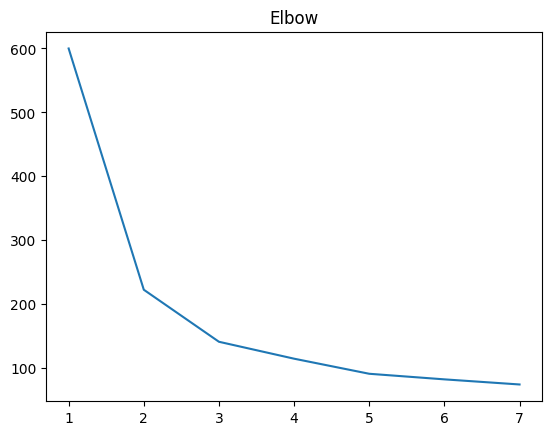

In [8]:
inertia = [] #lista pra armazenar valor de cada teste
for i in range (1,8):
    kmeans = KMeans(n_clusters=i, n_init="auto")
    kmeans.fit(clust1)
    inertia.append(kmeans.inertia_)

plt.plot(range(1,8), inertia)
plt.title("Elbow")
plt.show()

 ^ o melhor seria 3 pois há maior mudança no angulo da linha

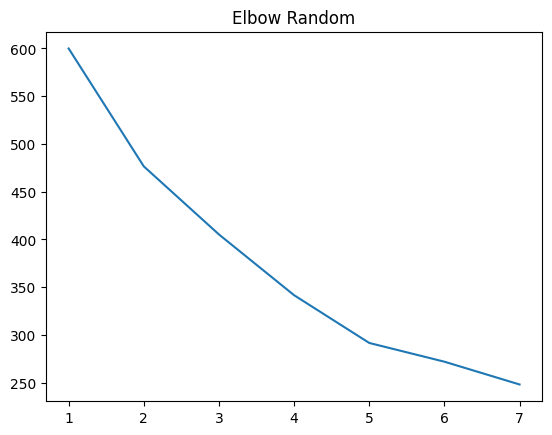

In [9]:
inertia_rd = []
for i in range(1,8):
    kmeans_rd = KMeans(n_clusters=i, n_init="auto")
    kmeans_rd.fit(clust2)
    inertia_rd.append(kmeans_rd.inertia_)

plt.plot(range(1,8), inertia_rd)
plt.title("Elbow Random")
plt.show()

^ Nesse caso com os valores randomicos o numero de Clusters seria de 5

>Apesar de que convencinalmente quanto mais proximo de 1, melhor o valor de hopkins, nessa biblioteca utilizada ele pega o complemento desse desse valor. ou seja 

Hopkins = 1 - (valor_real_de_hopkins) 

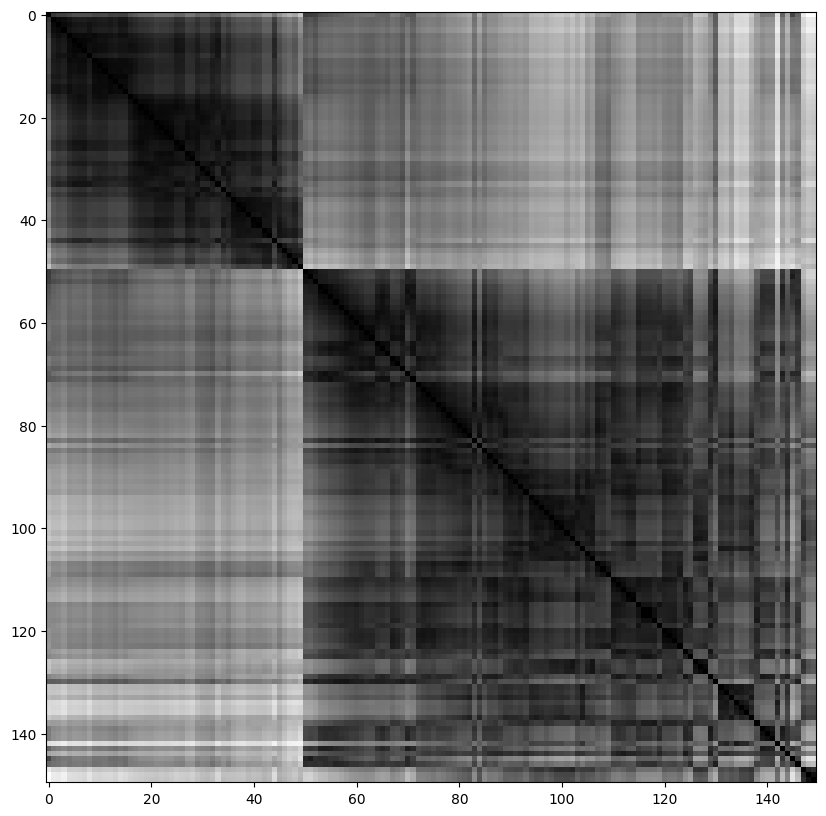

In [17]:
vat(clust1)

In [ ]:
print(hopkins(clust1, 150))
print("\nOu\n")
print(1 - hopkins(clust1, 150)) # como convencionalmente colocado

0.17430701278655494

Ou

0.8177762845612372


Com esse valor podemos ver que existe uma certa clareza nos dados

Mas quando tentamos com o cluster com valores randomicos:

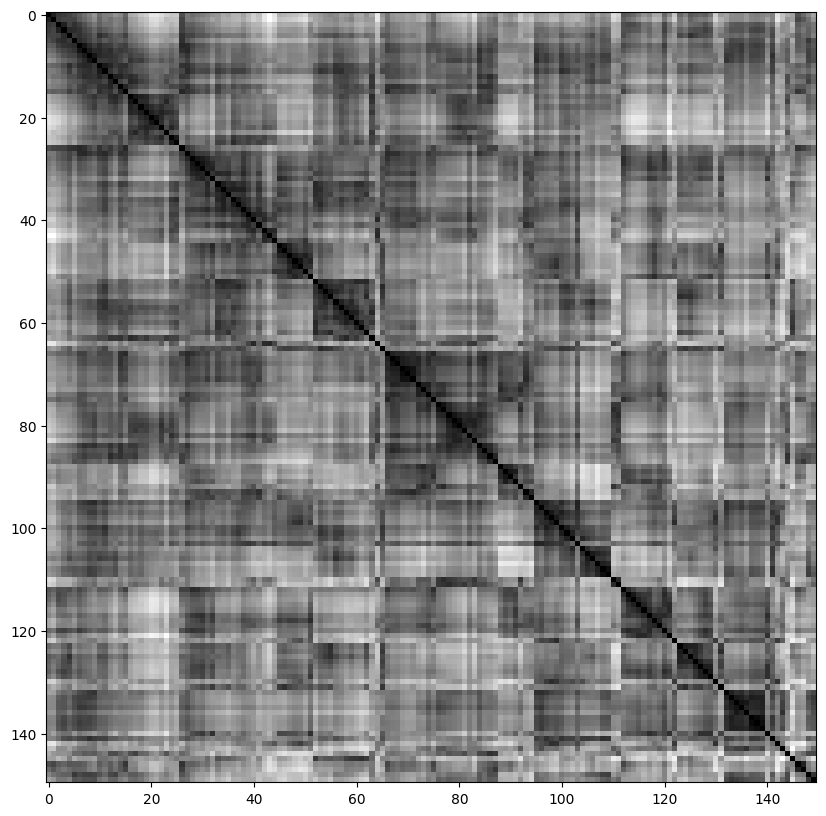

In [18]:
vat(clust2)

In [16]:
print(1 - hopkins(clust2, 150))

0.48884014768840867


Pode-se ver que apresenta valor proximo a 0.5, ou seja, dados estão de fato aleatorios